# k-NN vs Voting V3

For V3, I wanted to see if NN V3 and V4 could help when the nearest training image was farther away. I tried their agreed label on those images and kept k-NN for the others.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / 'src').is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.data_loader import load_task, split_train_val
from src.models.knn import KNNClassifier, euclidean_distance

result_dir = project_root / 'results/model_comparison'
result_dir.mkdir(parents=True, exist_ok=True)

I loaded the image data with the same split as V2 and checked that the saved predictions matched the validation samples.

In [2]:
X, y, X_test, test_ids = load_task('image')
X_train, X_val, y_train, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
assert X_train.shape == (16000, 500) and X_val.shape == (4000, 500)
assert X.shape == (20000, 500) and X_test.shape == (5000, 500)
assert X.dtype == X_train.dtype == X_val.dtype == X_test.dtype == np.float32
baseline = pd.read_csv(result_dir / 'knn_vs_voting_v2_knn16k_validation.csv')
nn3 = pd.read_csv(project_root / 'results/image/nn_v3_validation.csv')
nn4 = pd.read_csv(project_root / 'results/image/nn_v4_validation.csv')
for frame in [baseline, nn3, nn4]:
    assert frame.columns.tolist() == ['validation_index', 'actual_label', 'predicted_label']
    assert len(frame) == 4000 and not frame.isna().any().any()
    assert frame.validation_index.is_unique
    assert np.array_equal(frame.validation_index, np.arange(4000))
    assert np.array_equal(frame.actual_label, y_val)
    for column in frame.columns:
        assert pd.api.types.is_integer_dtype(frame[column])
    assert frame.actual_label.between(0, 49).all() and frame.predicted_label.between(0, 49).all()
knn_predictions = baseline.predicted_label.to_numpy()

I calculated the distance to the closest training image using the original features and Euclidean distance.

In [3]:
def nearest_images(model, features):
    nearest_distances = []
    nearest_labels = []
    for image in features:
        distances = euclidean_distance(image, model.X_train)
        nearest = int(np.argmin(distances))
        nearest_distances.append(distances[nearest])
        nearest_labels.append(model.y_train[nearest])
    return np.asarray(nearest_distances), np.asarray(nearest_labels)

model = KNNClassifier(k=1, distance_fn=euclidean_distance, voting_method='majority')
model.fit(X_train, y_train)
start = perf_counter()
validation_distances, nearest_labels = nearest_images(model, X_val)
assert len(validation_distances) == 4000 and np.isfinite(validation_distances).all()
assert validation_distances.dtype == np.float32
assert np.array_equal(nearest_labels, knn_predictions)
assert np.array_equal(model.predict(X_val[:5]), nearest_labels[:5])
cutoff = np.percentile(validation_distances[:2000], 85)
print('Validation distance cutoff:', cutoff)
print(f'Validation distances calculated in {perf_counter() - start:.6f} s')

Validation distance cutoff: 1.1146302819252014
Validation distances calculated in 204.557331 s


Then I used the NN label only when NN V3 and V4 agreed and the nearest distance was at least the fixed cutoff.

In [4]:
def conditional_vote(knn_labels, distances, nn3_labels, nn4_labels, cutoff):
    assert len(knn_labels) == len(distances) == len(nn3_labels) == len(nn4_labels)
    use_nn = (distances >= cutoff) & (nn3_labels == nn4_labels)
    predictions = knn_labels.copy()
    predictions[use_nn] = nn3_labels[use_nn]
    return predictions, use_nn

v3_predictions, use_nn = conditional_vote(
    knn_predictions, validation_distances, nn3.predicted_label.to_numpy(),
    nn4.predicted_label.to_numpy(), cutoff)
assert np.array_equal(v3_predictions[~use_nn], knn_predictions[~use_nn])
assert np.array_equal(v3_predictions[use_nn], nn3.predicted_label.to_numpy()[use_nn])
assert ((v3_predictions >= 0) & (v3_predictions <= 49)).all()
validation = pd.DataFrame({'validation_index': np.arange(4000),
    'actual_label': y_val, 'predicted_label': v3_predictions})
validation.to_csv(result_dir / 'knn_vs_voting_v3_image_validation.csv', index=False)
rows = []
for name, predictions, setting in [
    ('k-NN 16k', knn_predictions, 'k=1, Euclidean distance, 16000 training images, no normalization'),
    ('Conditional vote V3', v3_predictions,
     'Use NN V3 and V4 agreement at or above the 85th percentile of the first 2000 validation distances; otherwise k-NN')]:
    correct = int((predictions == y_val).sum())
    rows.append({'candidate': name, 'correct_count': correct, 'validation_samples': len(y_val),
                 'validation_accuracy': correct / len(y_val), 'setting': setting})
summary = pd.DataFrame(rows)
summary.to_csv(result_dir / 'knn_vs_voting_v3_summary.csv', index=False)
print(summary[['candidate', 'correct_count', 'validation_samples', 'validation_accuracy']].to_string(index=False))

          candidate  correct_count  validation_samples  validation_accuracy
           k-NN 16k           2077                4000              0.51925
Conditional vote V3           2102                4000              0.52550


I also compared the results in both halves of the validation set to see if the change helped in both.

In [5]:
groups = []
for name, start, end in [('All', 0, 4000), ('0..1999', 0, 2000), ('2000..3999', 2000, 4000)]:
    old_correct = int((knn_predictions[start:end] == y_val[start:end]).sum())
    new_correct = int((v3_predictions[start:end] == y_val[start:end]).sum())
    groups.append({'validation_group': name, 'validation_samples': end-start,
        'baseline_correct_count': old_correct, 'new_correct_count': new_correct,
        'changed_count': int((v3_predictions[start:end] != knn_predictions[start:end]).sum()),
        'gained_correct_predictions': new_correct-old_correct,
        'nn_agreement_distance_cases': int(use_nn[start:end].sum())})
distance_groups = pd.DataFrame(groups)
distance_groups.to_csv(result_dir / 'knn_vs_voting_v3_distance_groups.csv', index=False)
print(distance_groups.to_string(index=False))

validation_group  validation_samples  baseline_correct_count  new_correct_count  changed_count  gained_correct_predictions  nn_agreement_distance_cases
             All                4000                    2077               2102            201                          25                          237
         0..1999                2000                    1005               1021            107                          16                          122
      2000..3999                2000                    1072               1081             94                           9                          115


I plotted the results beside the earlier image votes.

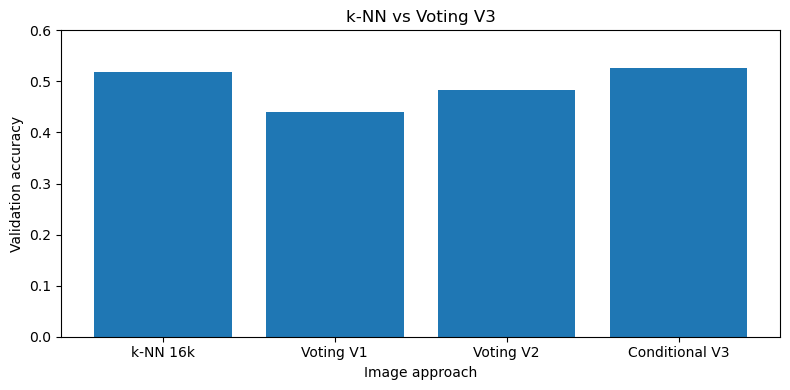

In [6]:
vote_v1 = pd.read_csv(result_dir / 'image_voted_validation.csv')
vote_v2 = pd.read_csv(result_dir / 'knn_vs_voting_v2_vote16k_validation.csv')
for frame in [vote_v1, vote_v2]:
    assert len(frame) == 4000 and frame.validation_index.is_unique
    assert np.array_equal(frame.validation_index, np.arange(4000))
    assert np.array_equal(frame.actual_label, y_val)
accuracies = [float((predictions == y_val).mean()) for predictions in
              [knn_predictions, vote_v1.predicted_label.to_numpy(),
               vote_v2.predicted_label.to_numpy(), v3_predictions]]
plt.figure(figsize=(8, 4))
plt.bar(['k-NN 16k', 'Voting V1', 'Voting V2', 'Conditional V3'], accuracies)
plt.xlabel('Image approach')
plt.ylabel('Validation accuracy')
plt.title('k-NN vs Voting V3')
plt.ylim(0, 0.6)
plt.tight_layout()
plt.savefig(result_dir / 'knn_vs_voting_v3_accuracy.png')
plt.show()

I kept NN V3 for sentiment and calculated the equal average of the two task accuracies.

In [7]:
sentiment = pd.read_csv(project_root / 'results/sentiment/nn_v3_validation.csv')
raw_sentiment_labels = pd.read_csv(project_root / 'data/raw/sentiment_train.csv', usecols=['label']).label.to_numpy()
_, _, _, sentiment_y_val = split_train_val(
    np.arange(len(raw_sentiment_labels)).reshape(-1, 1), raw_sentiment_labels,
    val_fraction=0.2, seed=42)
assert len(sentiment) == 2400 and not sentiment.isna().any().any()
assert sentiment.validation_index.is_unique
assert np.array_equal(sentiment.validation_index, np.arange(2400))
assert np.array_equal(sentiment.actual_label, sentiment_y_val)
for column in ['validation_index', 'actual_label', 'predicted_label']:
    assert pd.api.types.is_integer_dtype(sentiment[column])
assert sentiment.predicted_label.between(0, 2).all()
sentiment_correct = int((sentiment.predicted_label == sentiment.actual_label).sum())
sentiment_accuracy = sentiment_correct / len(sentiment)
image_accuracy = float((v3_predictions == y_val).mean())
combined_accuracy = (image_accuracy + sentiment_accuracy) / 2
print(f'NN V3 sentiment: {sentiment_correct}/{len(sentiment)}, accuracy={sentiment_accuracy!r}')
print('Combined validation accuracy:', combined_accuracy)

NN V3 sentiment: 1639/2400, accuracy=0.6829166666666666
Combined validation accuracy: 0.6042083333333332


For the test images, I used all 20000 labeled images and set the cutoff from the test distances at the same 85th percentile.

In [8]:
test_model = KNNClassifier(k=1, distance_fn=euclidean_distance, voting_method='majority')
test_model.fit(X, y)
start = perf_counter()
test_distances, test_knn_labels = nearest_images(test_model, X_test)
assert len(test_distances) == len(test_knn_labels) == len(test_ids) == 5000
assert np.isfinite(test_distances).all() and test_distances.dtype == np.float32
assert np.array_equal(test_model.predict(X_test[:5]), test_knn_labels[:5])
test_cutoff = np.percentile(test_distances, 85)
print('Test distance cutoff:', test_cutoff)
print(f'Test neighbors calculated in {perf_counter() - start:.6f} s')

Test distance cutoff: 1.1097951114177704
Test neighbors calculated in 233.992831 s


Then I matched the saved NN predictions by ID and applied the same conditional rule to images.

In [9]:
sample = pd.read_csv(project_root / 'data/raw/sample_submission.csv')
text_ids = pd.read_csv(project_root / 'data/raw/sentiment_test.csv', usecols=['id']).id
assert sample.columns.tolist() == ['id', 'label']
assert len(sample) == 10000 and sample.id.is_unique and not sample.isna().any().any()
assert len(set(test_ids)) == 5000 and len(text_ids) == 5000 and text_ids.is_unique
assert all(str(sample_id).startswith('img_') for sample_id in test_ids)
assert text_ids.str.startswith('text_').all()
assert set(test_ids).isdisjoint(set(text_ids))
assert set(sample.id) == set(test_ids) | set(text_ids)
is_image = sample.id.isin(test_ids)
is_text = sample.id.isin(text_ids)

def align_submission(path, ids):
    frame = pd.read_csv(path)
    assert frame.columns.tolist() == ['id', 'label']
    assert len(frame) == 10000 and frame.id.is_unique and not frame.isna().any().any()
    assert set(frame.id) == set(sample.id)
    assert pd.api.types.is_integer_dtype(frame.label)
    assert frame.loc[frame.id.isin(test_ids), 'label'].between(0, 49).all()
    assert frame.loc[frame.id.isin(text_ids), 'label'].between(0, 2).all()
    aligned = pd.DataFrame({'id': ids}).merge(frame, on='id', how='left', sort=False, validate='one_to_one')
    assert aligned.id.tolist() == list(ids) and not aligned.isna().any().any()
    return aligned

nn3_images = align_submission(project_root / 'submission/nn/submission_v3_nn.csv', test_ids)
nn4_images = align_submission(project_root / 'submission/nn/submission_v4_nn.csv', test_ids)
previous_knn = align_submission(project_root / 'submission/knn/submission_final_knn.csv', test_ids)
assert np.array_equal(test_knn_labels, previous_knn.label.to_numpy())
test_predictions, test_use_nn = conditional_vote(test_knn_labels, test_distances,
    nn3_images.label.to_numpy(), nn4_images.label.to_numpy(), test_cutoff)
assert np.array_equal(test_predictions[~test_use_nn], test_knn_labels[~test_use_nn])
assert np.array_equal(test_predictions[test_use_nn], nn3_images.label.to_numpy()[test_use_nn])
print('Image labels changed from full-data k-NN:', int((test_predictions != test_knn_labels).sum()))

Image labels changed from full-data k-NN: 236


Finally, I combined the image predictions with NN V3 sentiment and saved the Kaggle CSV.

In [10]:
image_predictions = pd.DataFrame({'id': test_ids, 'label': test_predictions})
sentiment_predictions = align_submission(project_root / 'submission/nn/submission_v3_nn.csv', text_ids)
predictions = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
assert len(predictions) == 10000 and predictions.id.is_unique
submission = sample[['id']].merge(predictions, on='id', how='left', sort=False, validate='one_to_one')
assert submission.columns.tolist() == ['id', 'label']
assert submission.id.tolist() == sample.id.tolist()
assert not submission.isna().any().any() and pd.api.types.is_integer_dtype(submission.label)
assert is_image.sum() == is_text.sum() == 5000
assert submission.loc[is_image, 'label'].between(0, 49).all()
assert submission.loc[is_text, 'label'].between(0, 2).all()
assert np.array_equal(submission.loc[is_text, 'label'],
    align_submission(project_root / 'submission/nn/submission_v3_nn.csv', sample.id).loc[is_text, 'label'])
for name, relative_path in [
    ('Voting V2', 'submissions/submission_knn_vs_voting_v2.csv'),
    ('Voting V1', 'submissions/submission_knn_nn_voting_v1.csv'),
    ('Earlier mixed submission', 'submission/nn/submission_final_nn.csv')]:
    previous = align_submission(project_root / relative_path, sample.id)
    changed = submission.label != previous.label
    print(name, 'changed image labels:', int((changed & is_image).sum()),
          'changed sentiment labels:', int((changed & is_text).sum()))
    assert int((changed & is_image).sum()) > 0 and int((changed & is_text).sum()) == 0
submission_dir = project_root / 'submissions'
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / 'submission_knn_vs_voting_v3.csv'
submission.to_csv(submission_path, index=False)
assert pd.read_csv(submission_path).equals(submission)
print('Saved', len(submission), 'predictions to', submission_path.relative_to(project_root))

Voting V2 changed image labels: 236 changed sentiment labels: 0
Voting V1 changed image labels: 1662 changed sentiment labels: 0
Earlier mixed submission changed image labels: 236 changed sentiment labels: 0


Saved 10000 predictions to submissions\submission_knn_vs_voting_v3.csv


V3 got 25 more images correct than k-NN alone. It was a small improvement, so I'll compare the Kaggle result before deciding which approach to keep.